# Phân khúc khách hàng bằng RFM + K-Means (và các mô hình đối chứng)

**Mục tiêu:** chia khách hàng của bộ dữ liệu *Online Retail* (UK, 12/2010 – 12/2011) thành các nhóm có hành vi mua hàng tương đồng, từ đó đề xuất chiến lược chăm sóc / marketing cho từng nhóm.

**Pipeline**

1. `src/etl_rfm.py` → `data/online_retail_clean.csv`, `data/rfm.csv` (phần tiền xử lý đã có).
2. `src/features.py` → `data/customer_features.csv`: rà soát lại dữ liệu clean và tính RFM *ròng* + vài đặc trưng hành vi phụ (mục 1).
3. Notebook này: biến đổi dữ liệu → 4 cách phân khúc → so sánh → chọn mô hình → mô tả nhóm → chiến lược.

| # | Mô hình | Vai trò |
|---|---|---|
| 0 | **RFM Scoring** (luật, chia ngũ phân vị) | Baseline dễ giải thích, chuẩn ngành |
| 1 | **K-Means** | Mô hình chính |
| 2 | **Gaussian Mixture Model (GMM)** | Phân cụm mềm – cho xác suất thuộc nhóm |
| 3 | **Hierarchical Clustering (Ward)** | Không cần chọn k trước, có dendrogram |

Kết quả xuất ra thư mục `outputs/` (file phân khúc từng khách + hình cho báo cáo).

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")  # tránh cảnh báo joblib trên Windows

import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
RFM = ["Recency", "Frequency", "Monetary"]

# Bảng màu phân loại cố định theo thứ tự (đã kiểm tra an toàn cho người mù màu).
SEGMENT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
SEGMENT_MARKERS = ["o", "s", "^", "D", "v"]
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.size": 10,
    "text.color": INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelcolor": INK_2,
    "axes.edgecolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")

## 1. Dữ liệu đầu vào & rà soát lại file clean

Khi rà lại `online_retail_clean.csv` thấy 3 vấn đề làm **Monetary bị thổi phồng**:

| Vấn đề | Quy mô | Xử lý trong `src/features.py` |
|---|---|---|
| Dòng giao dịch trùng lặp hoàn toàn | 5.192 dòng | `drop_duplicates()` |
| Mã không phải sản phẩm: `POST`, `DOT`, `C2` (phí ship), `M` (manual), `BANK CHARGES`, `PADS` | ~1.550 dòng, ~150k £ | Chỉ giữ `StockCode` bắt đầu bằng 5 chữ số |
| Đơn đã bị hủy: ETL bỏ hóa đơn `C...` nhưng vẫn giữ đơn gốc → khách mua rồi hủy vẫn được tính tiền (vd. khách 16446 đặt 80.995 sản phẩm rồi hủy ngay → M = 168k £) | 8.506 dòng hủy, 1.5k khách | Đọc dòng hủy từ file Excel gốc, **Monetary = tổng mua − tổng hủy** |

Sau khi trừ hủy, 18 khách có Monetary ≤ 0 (trả lại toàn bộ) bị loại → còn **4.320 khách**.

Ngoài R, F, M, file đặc trưng có thêm các cột *chỉ dùng để mô tả nhóm* (không đưa vào phân cụm): `Tenure` (số ngày từ lần mua đầu), `AvgOrderValue`, `UniqueProducts`, `TotalItems`, `ReturnRate`, `Country`.

> Nếu chưa có `data/customer_features.csv`, chạy `python src/features.py` (mất ~1 phút vì đọc file Excel gốc).

In [2]:
features_path = DATA_DIR / "customer_features.csv"
if not features_path.exists():
    raise FileNotFoundError("Chưa có data/customer_features.csv — chạy `python src/features.py` trước.")

customers = pd.read_csv(features_path)
old_rfm = pd.read_csv(DATA_DIR / "rfm.csv")
print(f"rfm.csv cũ: {len(old_rfm):,} khách | customer_features.csv: {len(customers):,} khách")
customers.head()

rfm.csv cũ: 4,338 khách | customer_features.csv: 4,320 khách


,CustomerID,Recency,Frequency,Monetary,Tenure,AvgOrderValue,UniqueProducts,TotalItems,ReturnRate,Country
0,"12,347.00",2,7,"4,310.00",367,615.71,103,2458,0.00,Iceland
1,"12,348.00",75,4,"1,437.24",358,359.31,21,2332,0.00,Finland
2,"12,349.00",19,1,"1,457.55",19,"1,457.55",72,630,0.00,Italy
3,"12,350.00",310,1,294.40,310,294.40,16,196,0.00,Norway
4,"12,352.00",36,7,"1,265.41",297,180.77,57,526,0.09,Norway


In [3]:
comparison = old_rfm.merge(customers[["CustomerID", *RFM]], on="CustomerID", how="left", suffixes=("_cũ", "_mới"))
comparison["Chênh_M"] = comparison["Monetary_cũ"] - comparison["Monetary_mới"].fillna(0)
print("Khách bị điều chỉnh Monetary nhiều nhất:")
comparison.nlargest(8, "Chênh_M")[["CustomerID", "Frequency_cũ", "Monetary_cũ", "Monetary_mới", "Chênh_M"]]

Khách bị điều chỉnh Monetary nhiều nhất:


,CustomerID,Frequency_cũ,Monetary_cũ,Monetary_mới,Chênh_M
3008,"16,446.00",2,"168,472.50",2.90,"168,469.60"
0,"12,346.00",1,"77,183.60",NaN,"77,183.60"
2502,"15,749.00",3,"44,534.30","21,535.90","22,998.40"
2702,"16,029.00",63,"81,024.84","60,369.93","20,654.91"
1879,"14,911.00",201,"143,825.06","128,768.24","15,056.82"
324,"12,744.00",7,"21,279.29","9,120.39","12,158.90"
1289,"14,096.00",17,"65,164.79","53,258.43","11,906.36"
453,"12,931.00",15,"42,055.96","33,544.81","8,511.15"


## 2. Khám phá RFM

R, F, M **lệch phải rất mạnh** (vài khách sỉ chi hàng trăm nghìn £, 1/3 khách chỉ mua 1 lần). K-Means dùng khoảng cách Euclid và tâm cụm là trung bình, nên nếu để nguyên thì các outlier sẽ chiếm hẳn một cụm riêng và phần lớn khách bị dồn vào một cụm. → Cần biến đổi **log** rồi **chuẩn hóa**.

In [4]:
print("Độ lệch (skewness) trước và sau log1p:")
pd.DataFrame({
    "Gốc": customers[RFM].skew(),
    "log1p": np.log1p(customers[RFM]).skew(),
}).T

Độ lệch (skewness) trước và sau log1p:


,Recency,Frequency,Monetary
Gốc,1.25,11.94,21.54
log1p,-0.38,1.21,0.37


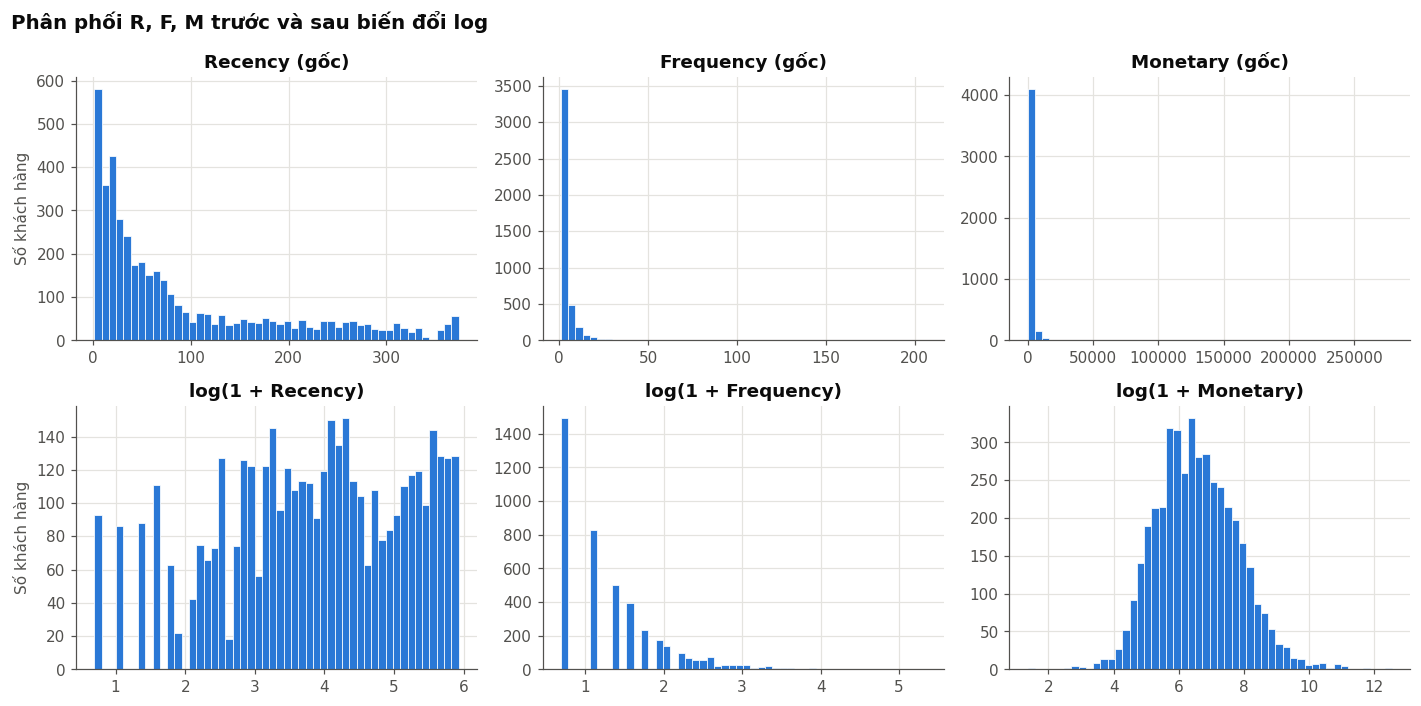

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for col, ax_raw, ax_log in zip(RFM, axes[0], axes[1]):
    ax_raw.hist(customers[col], bins=50, color=SEGMENT_COLORS[0], edgecolor="white", linewidth=0.5)
    ax_raw.set_title(f"{col} (gốc)")
    ax_log.hist(np.log1p(customers[col]), bins=50, color=SEGMENT_COLORS[0], edgecolor="white", linewidth=0.5)
    ax_log.set_title(f"log(1 + {col})")
for ax in axes[:, 0]:
    ax.set_ylabel("Số khách hàng")
fig.suptitle("Phân phối R, F, M trước và sau biến đổi log", fontsize=13, fontweight="semibold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "01_rfm_distribution")
plt.show()

In [6]:
print("Tương quan Spearman giữa R, F, M:")
customers[RFM].corr(method="spearman")

Tương quan Spearman giữa R, F, M:


,Recency,Frequency,Monetary
Recency,1.00,-0.56,-0.48
Frequency,-0.56,1.00,0.81
Monetary,-0.48,0.81,1.00


F và M tương quan khá mạnh (khách mua nhiều lần thì tổng chi cao), R tương quan âm với F. Ba chiều vẫn mang thông tin khác nhau nên giữ cả ba.

## 3. Tiền xử lý cho phân cụm

- `log1p` để giảm lệch (dùng `log1p` thay vì `log` cho an toàn với giá trị nhỏ).
- `StandardScaler` để 3 chiều có cùng thang đo (Recency tính bằng ngày, Monetary tính bằng £ — nếu không chuẩn hóa thì Monetary sẽ lấn át).

Ma trận `X` (4.320 × 3) này được dùng chung cho K-Means, GMM và Hierarchical.

In [7]:
scaler = StandardScaler()
X = scaler.fit_transform(np.log1p(customers[RFM]))
X_df = pd.DataFrame(X, columns=RFM)
X_df.describe().loc[["mean", "std", "min", "max"]]

,Recency,Frequency,Monetary
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.34,-0.95,-4.16
max,1.56,5.85,4.79


In [8]:
def relabel_by_value(labels):
    # Đánh số lại cụm theo "giá trị" của tâm cụm: 0 = tốt nhất (R thấp, F và M cao).
    centers = X_df.groupby(labels).mean()
    value = -centers["Recency"] + centers["Frequency"] + centers["Monetary"]
    order = value.sort_values(ascending=False).index
    mapping = {old: new for new, old in enumerate(order)}
    return pd.Series(labels).map(mapping).to_numpy()


def cluster_metrics(labels):
    return {
        "Silhouette ↑": silhouette_score(X, labels),
        "Davies-Bouldin ↓": davies_bouldin_score(X, labels),
        "Calinski-Harabasz ↑": calinski_harabasz_score(X, labels),
    }

## 4. Mô hình 0 — RFM Scoring (baseline theo luật)

Mỗi chỉ số được chia thành 5 mức bằng ngũ phân vị (quintile):
- **R_Score**: 5 = mua gần đây nhất, 1 = lâu nhất.
- **F_Score**, **M_Score**: 5 = cao nhất.

(F có rất nhiều giá trị trùng — 1/3 khách có F = 1 — nên xếp hạng bằng `rank(method="first")` trước khi chia.)

Phân khúc theo bảng ánh xạ (R, F) phổ biến trong marketing:

| R \ F | 1–2 | 3–4 | 5 |
|---|---|---|---|
| **5** | New (1) / Potential Loyalists (2) | Potential Loyalists (3) / Champions (4) | Champions |
| **4** | Promising (1) / Potential Loyalists (2–3) | Loyal (4) | Loyal |
| **3** | About to Sleep | Need Attention (3) / Loyal (4) | Loyal |
| **1–2** | Hibernating | At Risk | Can't Lose Them |

In [9]:
def quintile_score(series, ascending=True):
    labels = [1, 2, 3, 4, 5] if ascending else [5, 4, 3, 2, 1]
    return pd.qcut(series.rank(method="first"), 5, labels=labels).astype(int)


customers["R_Score"] = quintile_score(customers["Recency"], ascending=False)
customers["F_Score"] = quintile_score(customers["Frequency"])
customers["M_Score"] = quintile_score(customers["Monetary"])
customers["RFM_Score"] = customers[["R_Score", "F_Score", "M_Score"]].sum(axis=1)

RFM_SEGMENT_MAP = {
    r"[1-2][1-2]": "Hibernating",
    r"[1-2][3-4]": "At Risk",
    r"[1-2]5": "Can't Lose Them",
    r"3[1-2]": "About to Sleep",
    r"33": "Need Attention",
    r"[3-4][4-5]": "Loyal",
    r"41": "Promising",
    r"51": "New",
    r"[4-5][2-3]": "Potential Loyalists",
    r"5[4-5]": "Champions",
}
rf_code = customers["R_Score"].astype(str) + customers["F_Score"].astype(str)
customers["RFM_Segment"] = rf_code.replace(RFM_SEGMENT_MAP, regex=True)

rfm_rule_summary = (
    customers.groupby("RFM_Segment")
    .agg(Customers=("CustomerID", "size"), Recency=("Recency", "median"),
         Frequency=("Frequency", "median"), Monetary=("Monetary", "median"), Revenue=("Monetary", "sum"))
    .assign(**{"% khách": lambda d: 100 * d["Customers"] / d["Customers"].sum(),
               "% doanh thu": lambda d: 100 * d["Revenue"] / d["Revenue"].sum()})
    .sort_values("Customers", ascending=False)
)
rfm_rule_summary

,Customers,Recency,Frequency,Monetary,Revenue,% khách,% doanh thu
RFM_Segment,,,,,,,
Hibernating,1072,219.00,1.00,274.01,"429,774.16",24.81,5.20
Loyal,814,29.00,5.00,"1,677.00","2,198,451.09",18.84,26.58
Champions,630,5.00,8.00,"2,549.47","4,192,123.38",14.58,50.69
At Risk,592,135.00,3.00,665.16,"601,768.58",13.70,7.28
Potential Loyalists,477,17.00,2.00,503.76,"319,955.56",11.04,3.87
About to Sleep,347,52.00,1.00,316.88,"152,296.62",8.03,1.84
Need Attention,187,51.00,2.00,617.65,"154,720.14",4.33,1.87
Promising,96,22.00,1.00,223.87,"33,433.66",2.22,0.40
Can't Lose Them,64,105.00,7.00,"2,099.18","171,744.80",1.48,2.08


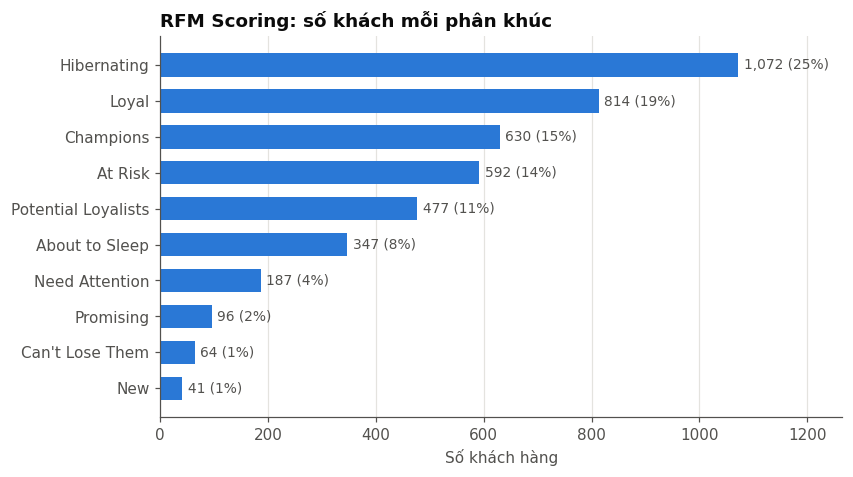

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
summary = rfm_rule_summary.sort_values("Customers")
ax.barh(summary.index, summary["Customers"], color=SEGMENT_COLORS[0], height=0.65)
for y, (count, share) in enumerate(zip(summary["Customers"], summary["% khách"])):
    ax.text(count + 10, y, f"{count:,} ({share:.0f}%)", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("Số khách hàng")
ax.set_title("RFM Scoring: số khách mỗi phân khúc", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, summary["Customers"].max() * 1.18)
save(fig, "02_rfm_scoring_segments")
plt.show()

**Nhận xét:** RFM Scoring dễ hiểu, không cần huấn luyện, nhưng ranh giới các nhóm là **ngưỡng cứng do người đặt** (ngũ phân vị + bảng ánh xạ), không học từ cấu trúc dữ liệu, và có tới 10 nhóm — nhiều nhóm nhỏ, khó triển khai chiến lược riêng. Các mô hình phân cụm bên dưới để dữ liệu tự quyết định ranh giới.

## 5. Mô hình 1 — K-Means

### 5.1 Chọn số cụm k

Chạy K-Means với k = 2..10 (`n_init=20` để tránh nghiệm cục bộ) và đánh giá bằng:
- **Elbow (Inertia/SSE)**: tìm điểm "gãy".
- **Silhouette** (càng cao càng tốt, ∈ [−1, 1]): cụm chặt và tách biệt.
- **Davies-Bouldin** (càng thấp càng tốt).
- **Calinski-Harabasz** (càng cao càng tốt).

In [11]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({"k": k, "Inertia": model.inertia_, **cluster_metrics(model.labels_)})
kmeans_selection = pd.DataFrame(rows).set_index("k")
kmeans_selection

,Inertia,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑
k,,,,
2,"6,453.31",0.43,0.89,"4,353.71"
3,"4,838.01",0.34,1.04,"3,623.69"
4,"3,909.27",0.34,1.01,"3,330.86"
5,"3,273.38",0.32,0.98,"3,192.35"
6,"2,832.97",0.31,1.01,"3,084.28"
7,"2,531.20",0.31,0.98,"2,961.77"
8,"2,317.89",0.30,0.99,"2,828.28"
9,"2,140.56",0.28,1.02,"2,723.80"
10,"1,984.84",0.28,1.01,"2,648.10"


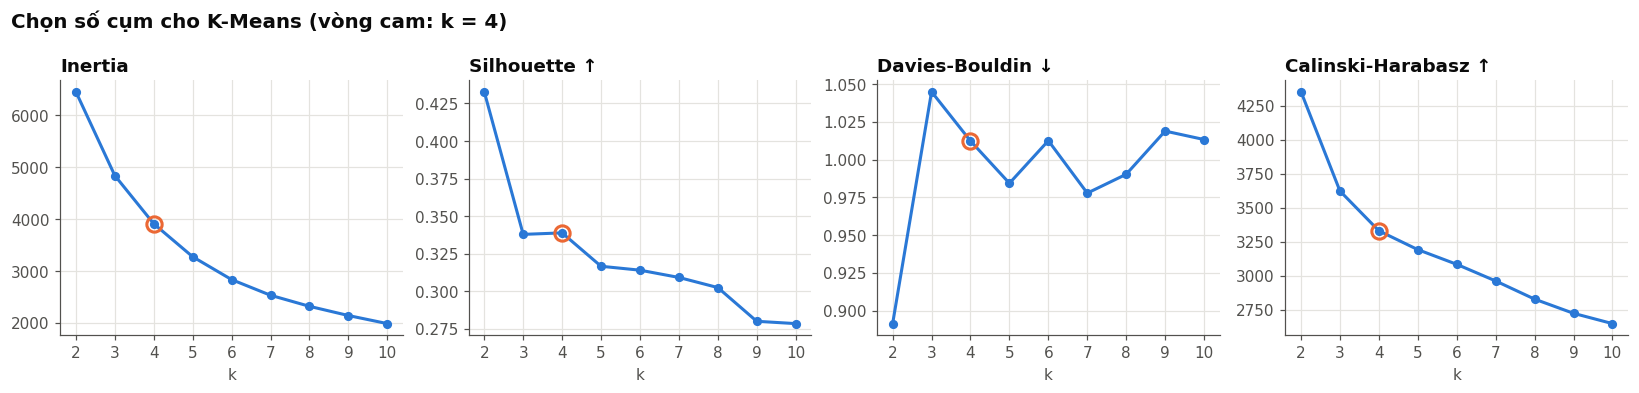

In [12]:
N_CLUSTERS = 4

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, kmeans_selection.columns):
    ax.plot(kmeans_selection.index, kmeans_selection[col], color=SEGMENT_COLORS[0], linewidth=2, marker="o", markersize=5)
    ax.plot(N_CLUSTERS, kmeans_selection.loc[N_CLUSTERS, col], marker="o", markersize=10,
            markerfacecolor="none", markeredgecolor=SEGMENT_COLORS[1], markeredgewidth=2)
    ax.set_title(col, loc="left")
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGE))
fig.suptitle(f"Chọn số cụm cho K-Means (vòng cam: k = {N_CLUSTERS})", fontsize=13, fontweight="semibold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "03_kmeans_choose_k")
plt.show()

**Chọn k = 4:**
- Silhouette cao nhất ở k = 2, nhưng 2 nhóm ("tốt" / "không tốt") quá thô để làm marketing. Bỏ k = 2, silhouette của k = 3 và k = 4 gần như bằng nhau (≈ 0,34) và giảm dần từ k = 5.
- Davies-Bouldin ở k = 4 tốt hơn k = 3.
- Đường Elbow bắt đầu thoải dần từ k ≈ 4.
- Về mặt kinh doanh, 4 nhóm đủ chi tiết để có chiến lược riêng mà vẫn dễ triển khai (k = 5 được xem xét ở mục 11).

### 5.2 Kiểm tra độ ổn định

K-Means phụ thuộc vào khởi tạo ngẫu nhiên. Chạy lại với 10 `random_state` khác nhau và so sánh nhãn bằng **Adjusted Rand Index** (ARI = 1 nghĩa là phân cụm giống hệt nhau).

In [13]:
stability = {}
for k in (3, 4, 5):
    runs = [KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X) for seed in range(10)]
    aris = [adjusted_rand_score(runs[0], run) for run in runs[1:]]
    stability[k] = {"ARI trung bình": np.mean(aris), "ARI nhỏ nhất": np.min(aris)}
pd.DataFrame(stability).T

,ARI trung bình,ARI nhỏ nhất
3,0.99,0.98
4,1.00,0.98
5,0.98,0.94


In [14]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=20, random_state=RANDOM_STATE).fit(X)
kmeans_labels = relabel_by_value(kmeans.labels_)
customers["KMeans_Cluster"] = kmeans_labels
print("Kích thước cụm:", np.bincount(kmeans_labels))
customers.groupby("KMeans_Cluster")[RFM].median()

Kích thước cụm: [ 685 1185  828 1622]


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,8.00,10.00,"3,622.95"
1,52.00,4.00,"1,315.72"
2,17.00,2.00,448.61
3,177.00,1.00,290.29


## 6. Mô hình 2 — Gaussian Mixture Model (GMM)

GMM giả định dữ liệu sinh ra từ k phân phối chuẩn nhiều chiều. Khác K-Means:
- Cụm có thể **hình elip, kích thước khác nhau** (K-Means ngầm giả định cụm tròn, cỡ tương đương).
- Cho **xác suất** mỗi khách thuộc từng cụm (soft clustering) → biết khách nào đang "lưng chừng" giữa hai nhóm.

Chọn k bằng **BIC** (càng thấp càng tốt). *Lưu ý:* Frequency là số nguyên và rất nhiều khách có F = 1, nên GMM mặc định có xu hướng đặt một thành phần "dẹt" lên đúng mặt phẳng F = 1 làm BIC giảm vô hạn khi tăng k. Dùng `reg_covar=0.1` (thêm 0,1 vào đường chéo hiệp phương sai) để hạn chế hiện tượng suy biến này.

**Kết quả:** BIC vẫn **không cho câu trả lời rõ ràng** — có cực tiểu cục bộ ở k = 3, rồi lại giảm ở k = 8 (thành phần suy biến quay lại). Vì vậy không dùng BIC để chọn k; GMM được chạy với **k = 4 giống K-Means** để so sánh công bằng.

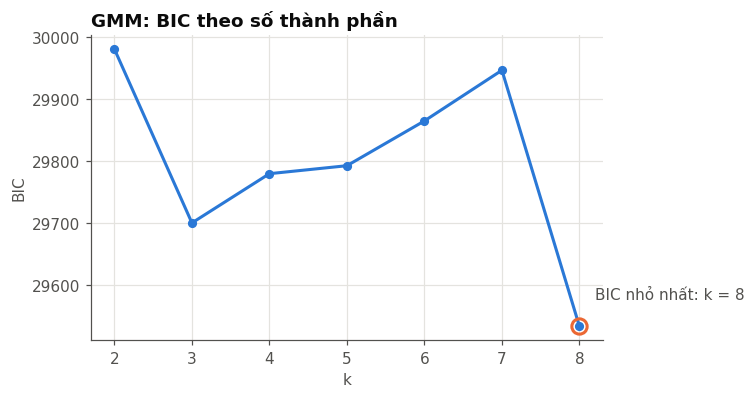

,BIC,AIC
k,,
2,"29,980.77","29,859.72"
3,"29,699.99","29,515.23"
4,"29,779.54","29,531.07"
5,"29,792.43","29,480.25"
6,"29,864.79","29,488.90"
7,"29,946.67","29,507.07"
8,"29,532.90","29,029.59"


In [15]:
gmm_rows = []
for k in range(2, 9):
    gmm_k = GaussianMixture(n_components=k, covariance_type="full", reg_covar=0.1,
                            n_init=5, random_state=RANDOM_STATE).fit(X)
    gmm_rows.append({"k": k, "BIC": gmm_k.bic(X), "AIC": gmm_k.aic(X)})
gmm_selection = pd.DataFrame(gmm_rows).set_index("k")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(gmm_selection.index, gmm_selection["BIC"], color=SEGMENT_COLORS[0], linewidth=2, marker="o", markersize=5)
best_k = gmm_selection["BIC"].idxmin()
ax.plot(best_k, gmm_selection.loc[best_k, "BIC"], marker="o", markersize=10,
        markerfacecolor="none", markeredgecolor=SEGMENT_COLORS[1], markeredgewidth=2)
ax.annotate(f"BIC nhỏ nhất: k = {best_k}", (best_k, gmm_selection.loc[best_k, "BIC"]),
            xytext=(10, 18), textcoords="offset points", color=INK_2)
ax.set_title("GMM: BIC theo số thành phần", loc="left")
ax.set_xlabel("k")
ax.set_ylabel("BIC")
save(fig, "04_gmm_bic")
plt.show()
gmm_selection

In [16]:
gmm = GaussianMixture(n_components=N_CLUSTERS, covariance_type="full", reg_covar=0.1,
                      n_init=5, random_state=RANDOM_STATE).fit(X)
gmm_labels = relabel_by_value(gmm.predict(X))
customers["GMM_Cluster"] = gmm_labels
customers["GMM_Confidence"] = gmm.predict_proba(X).max(axis=1)

uncertain_share = (customers["GMM_Confidence"] < 0.7).mean()
print(f"Tỷ lệ khách có xác suất thuộc cụm cao nhất < 0.7: {uncertain_share:.1%}")
customers.groupby("GMM_Cluster")[RFM].median().assign(Customers=customers["GMM_Cluster"].value_counts().sort_index())

Tỷ lệ khách có xác suất thuộc cụm cao nhất < 0.7: 51.4%


,Recency,Frequency,Monetary,Customers
GMM_Cluster,,,,
0,4.00,19.00,"7,272.75",235
1,24.00,5.00,"1,545.14",1633
2,7.00,2.00,339.87,218
3,124.00,1.00,324.93,2234


## 7. Mô hình 3 — Hierarchical Clustering (Ward)

Phân cụm phân cấp gộp dần (agglomerative): bắt đầu mỗi khách là 1 cụm, mỗi bước gộp 2 cụm mà làm tăng phương sai trong cụm ít nhất (**Ward linkage**). Ưu điểm: không cần chọn k trước, **dendrogram** cho thấy cấu trúc lồng nhau của các nhóm; nhược điểm: O(n²) bộ nhớ nên chỉ hợp với dữ liệu vừa phải (4.3k khách vẫn ổn).

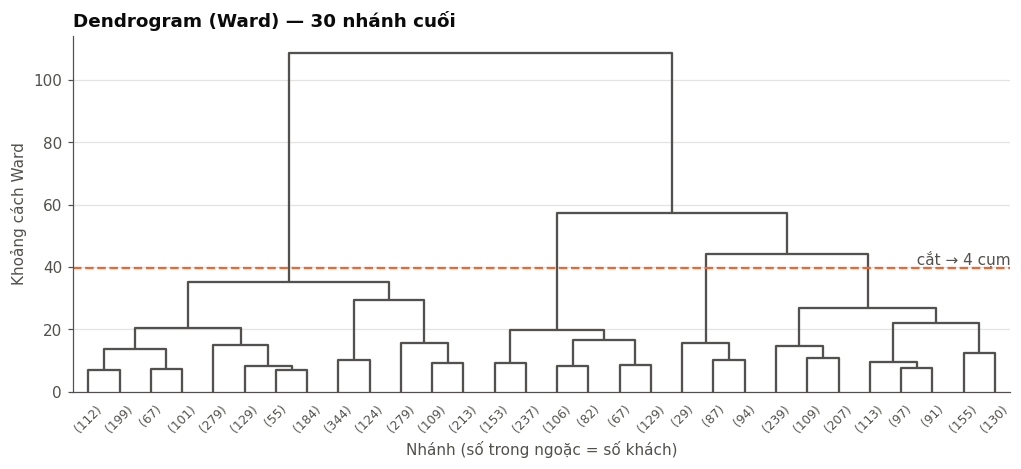

,Recency,Frequency,Monetary,Customers
HC_Cluster,,,,
0,3.00,19.00,"6,690.03",210
1,26.00,6.00,"2,140.07",1141
2,16.00,2.00,633.44,774
3,130.00,1.00,330.03,2195


In [17]:
ward_tree = linkage(X, method="ward")
cut_height = (ward_tree[-N_CLUSTERS, 2] + ward_tree[-N_CLUSTERS + 1, 2]) / 2

fig, ax = plt.subplots(figsize=(11, 4.2))
dendrogram(ward_tree, truncate_mode="lastp", p=30, ax=ax, link_color_func=lambda _: INK_2, leaf_font_size=8)
ax.axhline(cut_height, color=SEGMENT_COLORS[1], linestyle="--", linewidth=1.5)
ax.text(ax.get_xlim()[1], cut_height, f"  cắt → {N_CLUSTERS} cụm", va="bottom", ha="right", color=INK_2)
ax.set_title("Dendrogram (Ward) — 30 nhánh cuối", loc="left")
ax.set_xlabel("Nhánh (số trong ngoặc = số khách)")
ax.set_ylabel("Khoảng cách Ward")
ax.grid(axis="x", visible=False)
save(fig, "05_hierarchical_dendrogram")
plt.show()

hc_labels = relabel_by_value(fcluster(ward_tree, N_CLUSTERS, criterion="maxclust"))
customers["HC_Cluster"] = hc_labels
customers.groupby("HC_Cluster")[RFM].median().assign(Customers=customers["HC_Cluster"].value_counts().sort_index())

## 8. So sánh các mô hình

### 8.1 Chỉ số nội tại
Tính trên cùng không gian `X` (log + chuẩn hóa). RFM Scoring có 10 nhóm và không tối ưu theo khoảng cách nên chỉ để tham khảo.

In [18]:
model_labels = {
    "RFM Scoring (10 nhóm)": customers["RFM_Segment"].astype("category").cat.codes.to_numpy(),
    "K-Means": kmeans_labels,
    "GMM": gmm_labels,
    "Hierarchical (Ward)": hc_labels,
}
comparison_table = pd.DataFrame({name: cluster_metrics(labels) for name, labels in model_labels.items()}).T
comparison_table["Nhóm nhỏ nhất (% khách)"] = [
    100 * np.bincount(labels).min() / len(labels) for labels in model_labels.values()
]
comparison_table["Nhóm lớn nhất (% khách)"] = [
    100 * np.bincount(labels).max() / len(labels) for labels in model_labels.values()
]
comparison_table

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Nhóm nhỏ nhất (% khách),Nhóm lớn nhất (% khách)
RFM Scoring (10 nhóm),0.10,1.54,"1,145.24",0.95,24.81
K-Means,0.34,1.01,"3,330.86",15.86,37.55
GMM,0.33,0.89,"2,570.05",5.05,51.71
Hierarchical (Ward),0.31,1.04,"2,780.22",4.86,50.81


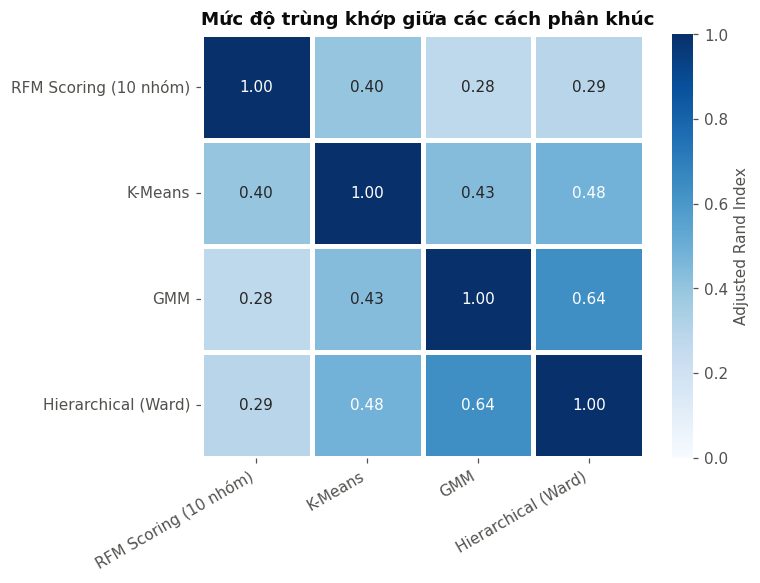

In [19]:
names = list(model_labels)
ari = pd.DataFrame(
    [[adjusted_rand_score(model_labels[a], model_labels[b]) for b in names] for a in names],
    index=names, columns=names,
)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"label": "Adjusted Rand Index"}, ax=ax)
ax.set_title("Mức độ trùng khớp giữa các cách phân khúc", loc="left")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
save(fig, "06_model_agreement_ari")
plt.show()

### 8.2 Chọn mô hình cuối: **K-Means (k = 4)**

- Silhouette (0,34) và Calinski-Harabasz cao nhất trong ba mô hình phân cụm cùng k = 4. GMM có Davies-Bouldin tốt hơn (0,89 so với 1,01), nhưng đổi lại các nhóm rất lệch (xem ý dưới).
- Kích thước nhóm cân đối nhất: nhóm nhỏ nhất vẫn chiếm ~16% khách. GMM và Ward đều tách ra một nhóm "siêu VIP" chỉ ~5% khách và dồn ~51% khách vào một nhóm mua ít — khó dùng cho marketing vì nhóm lớn nhất quá đa dạng.
- Rất ổn định giữa các lần khởi tạo (ARI ≥ 0,98).
- Tâm cụm dễ giải thích cho bộ phận marketing; dự đoán nhóm cho khách mới chỉ cần tính khoảng cách đến 4 tâm.

GMM được giữ làm **bổ trợ**: tới ~51% khách có xác suất thuộc cụm cao nhất < 0,7, cho thấy dữ liệu RFM **liên tục, không có khoảng trống rõ rệt giữa các nhóm** — ranh giới cụm là tương đối. Cột `GMM_Confidence` giúp đánh dấu những khách "lưng chừng" (vd. khách Trung thành sắp trượt xuống Ngủ đông) để ưu tiên chăm sóc.

Mức trùng khớp giữa K-Means với GMM (ARI ≈ 0,43) và Ward (≈ 0,48) chỉ ở mức trung bình, trong khi GMM và Ward giống nhau hơn (≈ 0,64) — hai mô hình này có chung xu hướng cô lập nhóm khách cực lớn. Điều này nhắc lại rằng ranh giới nhóm phụ thuộc vào giả định của thuật toán; các nhóm ở *đầu mút* (VIP, Ngủ đông) nhất quán giữa các mô hình, còn nhóm ở giữa thì kém nhất quán hơn.

## 9. Mô tả và đặt tên các nhóm (K-Means)

In [20]:
profile = customers.groupby("KMeans_Cluster").agg(
    Customers=("CustomerID", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    AvgOrderValue=("AvgOrderValue", "median"),
    Tenure=("Tenure", "median"),
    UniqueProducts=("UniqueProducts", "median"),
    ReturnRate=("ReturnRate", "mean"),
    Revenue=("Monetary", "sum"),
    UK_Share=("Country", lambda c: (c == "United Kingdom").mean()),
)
profile["% khách"] = 100 * profile["Customers"] / profile["Customers"].sum()
profile["% doanh thu"] = 100 * profile["Revenue"] / profile["Revenue"].sum()
profile

,Customers,Recency,Frequency,Monetary,AvgOrderValue,Tenure,UniqueProducts,ReturnRate,Revenue,UK_Share,% khách,% doanh thu
KMeans_Cluster,,,,,,,,,,,,
0,685,8.00,10.00,"3,622.95",360.33,358.00,117.00,0.02,"5,297,698.28",0.89,15.86,64.06
1,1185,52.00,4.00,"1,315.72",346.15,281.00,61.00,0.02,"1,981,904.94",0.89,27.43,23.97
2,828,17.00,2.00,448.61,218.70,65.00,30.00,0.01,"435,863.02",0.91,19.17,5.27
3,1622,177.00,1.00,290.29,219.19,219.50,17.00,0.02,"554,171.08",0.91,37.55,6.70


In [21]:
# Đặt tên dựa trên đặc điểm trung vị của từng cụm (không phụ thuộc thứ tự nhãn).
median_profile = profile[["Recency", "Frequency", "Monetary", "Tenure"]]
segment_names = {
    median_profile["Monetary"].idxmax(): "VIP",
    median_profile["Recency"].idxmax(): "Ngủ đông",
}
remaining = median_profile.drop(index=list(segment_names))
segment_names[remaining["Tenure"].idxmin()] = "Khách mới"
segment_names[remaining["Tenure"].idxmax()] = "Trung thành tiềm năng"
assert len(segment_names) == N_CLUSTERS, segment_names

SEGMENT_ORDER = [segment_names[c] for c in sorted(segment_names)]
customers["Segment"] = customers["KMeans_Cluster"].map(segment_names)
profile.index = profile.index.map(segment_names)
profile.index.name = "Segment"
segment_palette = dict(zip(SEGMENT_ORDER, SEGMENT_COLORS))
SEGMENT_ORDER

['VIP', 'Trung thành tiềm năng', 'Khách mới', 'Ngủ đông']

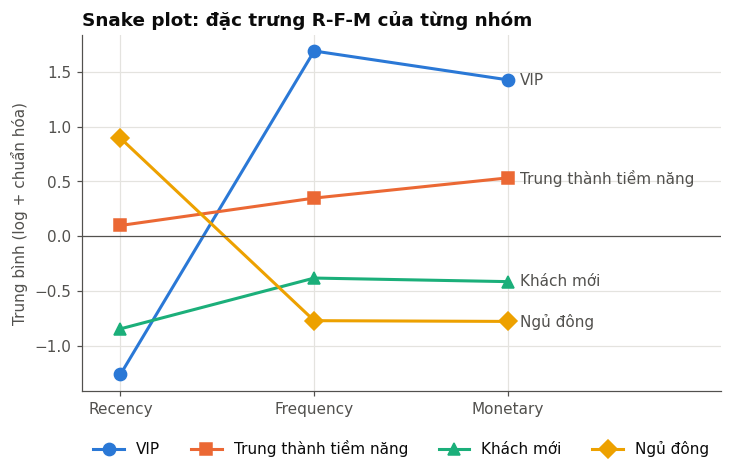

In [22]:
z_means = X_df.groupby(customers["Segment"]).mean().reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, segment in enumerate(SEGMENT_ORDER):
    ax.plot(RFM, z_means.loc[segment], color=SEGMENT_COLORS[i], linewidth=2,
            marker=SEGMENT_MARKERS[i], markersize=8, label=segment)
    ax.annotate(segment, (2, z_means.loc[segment, "Monetary"]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK_2)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_ylabel("Trung bình (log + chuẩn hóa)")
ax.set_title("Snake plot: đặc trưng R-F-M của từng nhóm", loc="left")
ax.set_xlim(-0.2, 3.1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
save(fig, "07_segment_snake_plot")
plt.show()

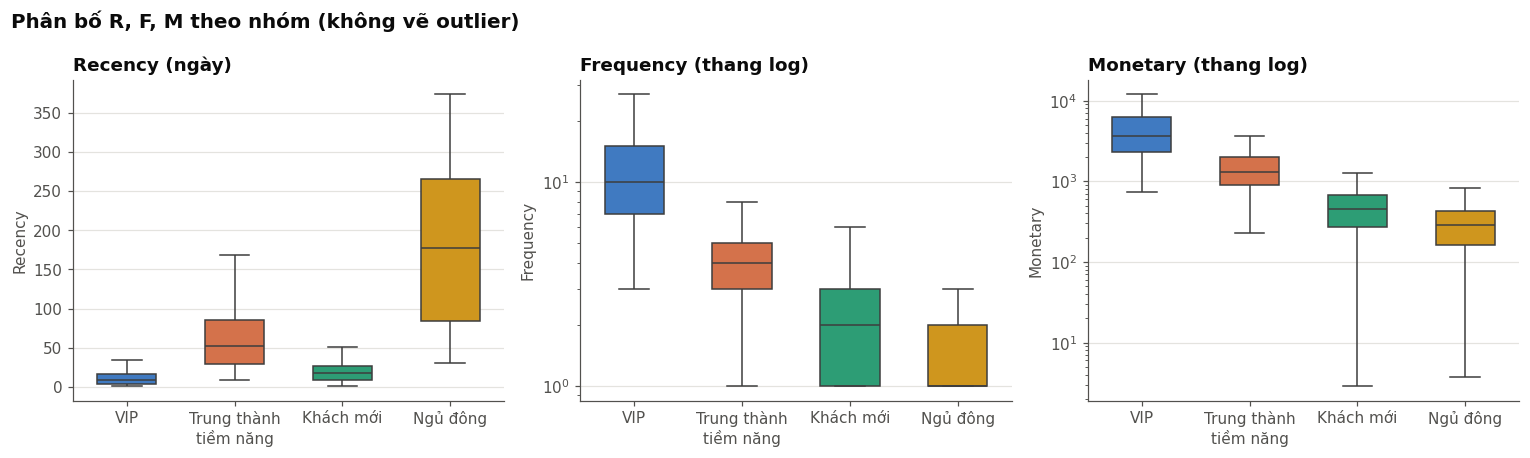

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col in zip(axes, RFM):
    sns.boxplot(data=customers, x="Segment", y=col, order=SEGMENT_ORDER, hue="Segment",
                palette=segment_palette, legend=False, showfliers=False, width=0.55, linewidth=1, ax=ax)
    if col != "Recency":
        ax.set_yscale("log")
    ax.set_title(col + (" (thang log)" if col != "Recency" else " (ngày)"), loc="left")
    ax.set_xlabel("")
    ax.set_xticks(range(N_CLUSTERS), [textwrap.fill(name, 12) for name in SEGMENT_ORDER])
fig.suptitle("Phân bố R, F, M theo nhóm (không vẽ outlier)", fontsize=13, fontweight="semibold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "08_segment_boxplots")
plt.show()

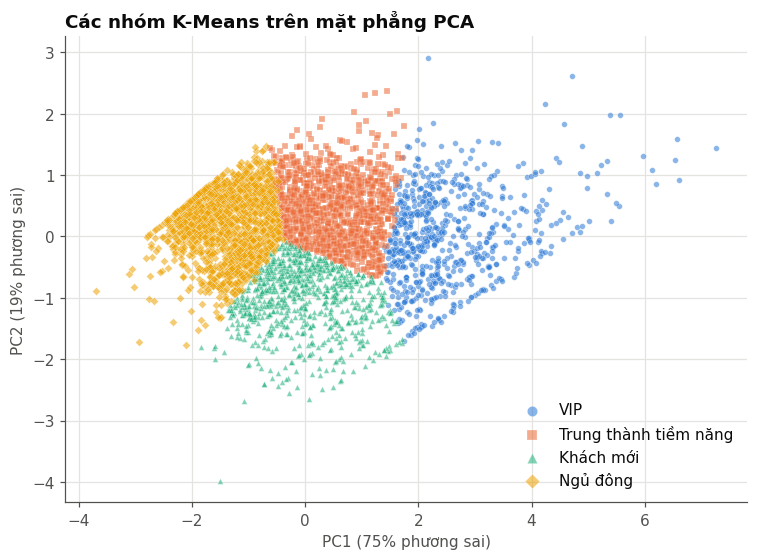

Hệ số tải (loadings) của PCA:


,Recency,Frequency,Monetary
PC1,-0.51,0.62,0.60
PC2,0.85,0.26,0.46


In [24]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 5.5))
for i, segment in enumerate(SEGMENT_ORDER):
    mask = (customers["Segment"] == segment).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], s=14, alpha=0.55, color=SEGMENT_COLORS[i],
               marker=SEGMENT_MARKERS[i], edgecolors="white", linewidths=0.3, label=segment)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} phương sai)")
ax.set_title("Các nhóm K-Means trên mặt phẳng PCA", loc="left")
ax.legend(markerscale=1.8, loc="best")
save(fig, "09_segment_pca")
plt.show()
print("Hệ số tải (loadings) của PCA:")
pd.DataFrame(pca.components_, columns=RFM, index=["PC1", "PC2"])

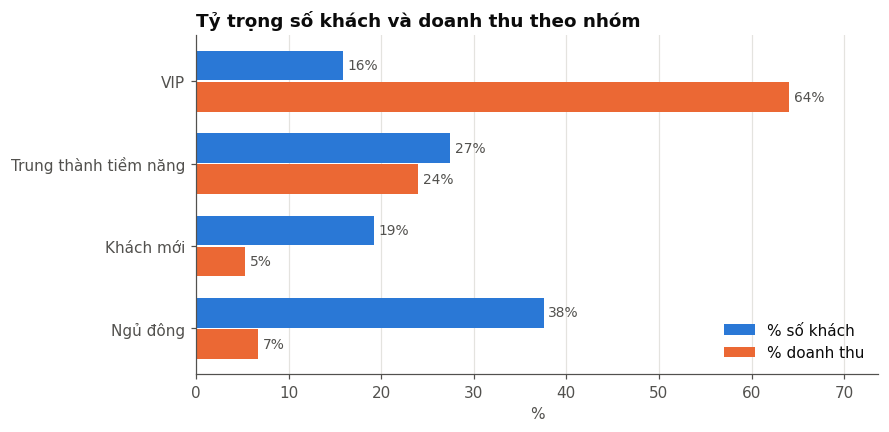

In [25]:
share = profile[["% khách", "% doanh thu"]].reindex(SEGMENT_ORDER)
y = np.arange(len(SEGMENT_ORDER))
fig, ax = plt.subplots(figsize=(8, 4))
bars_customers = ax.barh(y - 0.19, share["% khách"], height=0.36, color=SEGMENT_COLORS[0], label="% số khách")
bars_revenue = ax.barh(y + 0.19, share["% doanh thu"], height=0.36, color=SEGMENT_COLORS[1], label="% doanh thu")
for bars in (bars_customers, bars_revenue):
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=9, color=INK_2)
ax.set_yticks(y, SEGMENT_ORDER)
ax.invert_yaxis()
ax.set_xlabel("%")
ax.set_xlim(0, share.to_numpy().max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title("Tỷ trọng số khách và doanh thu theo nhóm", loc="left")
ax.legend(loc="lower right")
save(fig, "10_segment_customer_vs_revenue")
plt.show()

Đối chiếu nhóm K-Means với phân khúc RFM Scoring (% theo hàng):


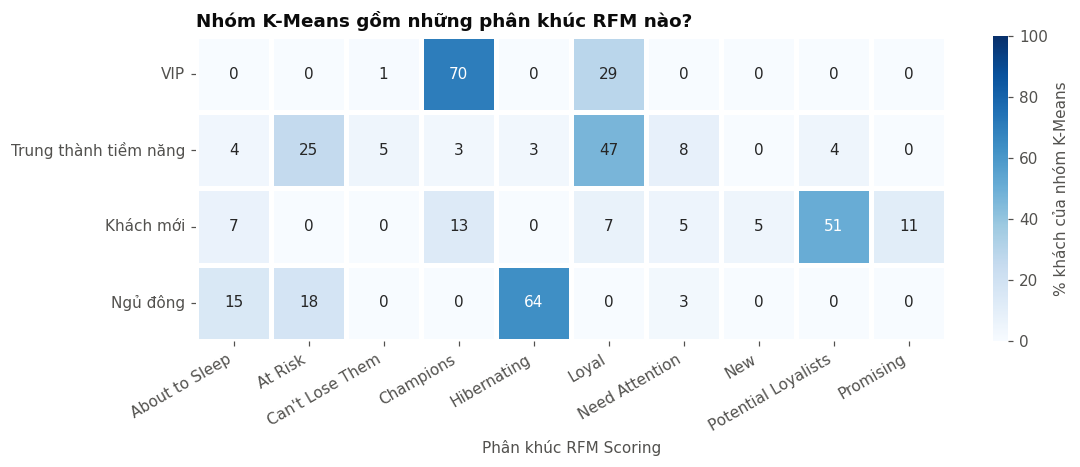

In [26]:
print("Đối chiếu nhóm K-Means với phân khúc RFM Scoring (% theo hàng):")
crosstab = pd.crosstab(customers["Segment"], customers["RFM_Segment"], normalize="index").reindex(SEGMENT_ORDER) * 100
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(crosstab, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=2, linecolor="white",
            cbar_kws={"label": "% khách của nhóm K-Means"}, ax=ax)
ax.set_xlabel("Phân khúc RFM Scoring")
ax.set_ylabel("")
ax.set_title("Nhóm K-Means gồm những phân khúc RFM nào?", loc="left")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
save(fig, "11_kmeans_vs_rfm_scoring")
plt.show()

### 9.1 Chân dung từng nhóm

*(Số liệu là trung vị, lấy từ bảng `profile` ở trên.)*

| Nhóm | Chân dung | Tương ứng RFM Scoring |
|---|---|---|
| **VIP** | Mua rất gần đây (~1 tuần), mua thường xuyên (~10 đơn/năm), chi tiêu cao nhất (~3.600 £), mua đa dạng (~117 mã sản phẩm), gắn bó gần cả năm. Chỉ **16% số khách nhưng mang lại 64% doanh thu**. | Champions (70%), Loyal (29%) |
| **Trung thành tiềm năng** | Mua lần cuối ~2 tháng trước, ~4 đơn, ~1.300 £, đã gắn bó lâu (~9 tháng). Giá trị khá (27% khách, 24% doanh thu) nhưng nhịp mua đang chậm lại — 1/4 nhóm này đã ở trạng thái *At Risk*. | Loyal (47%), At Risk (25%), Need Attention (8%) |
| **Khách mới** | Mua gần đây (~2–3 tuần) nhưng mới bắt đầu (Tenure ~2 tháng), ~2 đơn, giá trị đơn thấp (~220 £). 19% khách, 5% doanh thu. Đây cũng là nhóm có ranh giới mờ nhất (độ tin cậy GMM trung vị chỉ ~0,5). | Potential Loyalists (51%), Champions (13%), Promising (11%) |
| **Ngủ đông** | ~6 tháng chưa quay lại, chỉ mua 1 lần, chi tiêu thấp nhất. Nhóm đông nhất (~38% khách) nhưng chỉ đóng góp ~7% doanh thu. | Hibernating (64%), At Risk (18%), About to Sleep (15%) |

*Tỷ lệ hoàn/hủy (`ReturnRate` ~1–2%) và tỷ lệ khách UK (~90%) gần như như nhau giữa các nhóm → khác biệt giữa các nhóm nằm ở nhịp mua và mức chi tiêu, không phải ở quốc gia hay hành vi trả hàng.*

## 10. Đề xuất chiến lược chăm sóc & marketing

| Nhóm | Mục tiêu | Chiến lược đề xuất | KPI theo dõi |
|---|---|---|---|
| **VIP** | Giữ chân, tăng giá trị trọn đời | • Chương trình khách hàng thân thiết hạng cao (tích điểm, ưu đãi độc quyền, quà sinh nhật).<br>• Cho trải nghiệm sớm sản phẩm/bộ sưu tập mới.<br>• Chăm sóc riêng (account manager cho khách sỉ lớn), ưu tiên giao hàng.<br>• **Không** giảm giá đại trà — tránh bào mòn biên lợi nhuận của nhóm vốn đã chi nhiều.<br>• Mời giới thiệu khách mới (referral). | Tỷ lệ giữ chân, tần suất mua, giá trị đơn |
| **Trung thành tiềm năng** | Đẩy lên VIP, ngăn trượt xuống Ngủ đông | • Cross-sell / up-sell dựa trên lịch sử mua (gợi ý sản phẩm bổ trợ, combo).<br>• Ưu đãi theo ngưỡng ("mua thêm X £ được freeship / giảm Y%") để tăng giá trị đơn.<br>• Nhắc mua lại theo chu kỳ mua cá nhân; ưu tiên những khách có `GMM_Confidence` thấp (đang lưng chừng). | Tỷ lệ chuyển lên VIP, Recency trung bình |
| **Khách mới** | Biến lần mua đầu thành thói quen | • Chuỗi email chào mừng / onboarding giới thiệu danh mục sản phẩm.<br>• Voucher cho **lần mua thứ hai** có hạn dùng ngắn (2–4 tuần).<br>• Thu thập phản hồi sau mua để cải thiện trải nghiệm. | Tỷ lệ mua lần 2 trong 60 ngày |
| **Ngủ đông** | Tái kích hoạt với chi phí thấp | • Chiến dịch win-back tự động (email "Chúng tôi nhớ bạn", ưu đãi giảm giá mạnh có thời hạn).<br>• Giới thiệu sản phẩm bán chạy / mùa vụ (dữ liệu có đỉnh mùa lễ cuối năm).<br>• Không phản hồi sau 2–3 lần → giảm tần suất liên lạc, tập trung ngân sách cho nhóm khác. | Tỷ lệ quay lại, chi phí / khách tái kích hoạt |

## 11. Phân tích độ nhạy: nếu chọn k = 5?

Để kiểm tra lựa chọn k = 4, xem k = 5 tách nhóm như thế nào:

In [27]:
kmeans_5 = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X)
customers["KMeans_k5"] = relabel_by_value(kmeans_5.labels_)
print("Hồ sơ trung vị khi k = 5:")
display(customers.groupby("KMeans_k5")[[*RFM, "Tenure"]].median().assign(Customers=customers["KMeans_k5"].value_counts().sort_index()))
print("Nhóm k = 4 (hàng) được chia sang các cụm k = 5 (cột), % theo hàng:")
pd.crosstab(customers["Segment"], customers["KMeans_k5"], normalize="index").reindex(SEGMENT_ORDER) * 100

Hồ sơ trung vị khi k = 5:


,Recency,Frequency,Monetary,Tenure,Customers
KMeans_k5,,,,,
0,5.00,16.00,"6,156.10",366.00,316
1,16.00,6.00,"1,791.84",289.00,959
2,81.00,3.00,975.54,268.00,1015
3,24.00,2.00,346.60,49.00,838
4,212.00,1.00,236.48,239.00,1192


Nhóm k = 4 (hàng) được chia sang các cụm k = 5 (cột), % theo hàng:


KMeans_k5,0,1,2,3,4
Segment,,,,,
VIP,46.13,53.87,0.00,0.00,0.00
Trung thành tiềm năng,0.00,36.29,63.71,0.00,0.00
Khách mới,0.00,19.32,1.45,79.23,0.00
Ngủ đông,0.00,0.00,15.29,11.22,73.49


Với k = 5, nhóm VIP được tách thành "siêu VIP" (F ~16, M ~6.000 £) và phần còn lại gộp với một phần Trung thành, đồng thời xuất hiện một nhóm "Cần chú ý" (Recency ~3 tháng). Đây là phương án hợp lý nếu doanh nghiệp muốn chăm sóc chi tiết hơn, nhưng silhouette giảm (0,34 → 0,32) và độ ổn định thấp hơn (ARI nhỏ nhất giữa các seed 0,94 so với 0,98) nên báo cáo chọn **k = 4** làm kết quả chính.

## 12. Xuất kết quả

In [28]:
segments_out = customers[[
    "CustomerID", *RFM, "R_Score", "F_Score", "M_Score", "RFM_Score", "RFM_Segment",
    "KMeans_Cluster", "Segment", "GMM_Cluster", "GMM_Confidence", "HC_Cluster",
]]
segments_out.to_csv(OUT_DIR / "customer_segments.csv", index=False)
profile.reindex(SEGMENT_ORDER).to_csv(OUT_DIR / "segment_profile.csv")
comparison_table.to_csv(OUT_DIR / "model_comparison.csv")

print("Đã lưu:")
for path in sorted(OUT_DIR.rglob("*.*")):
    print(" -", path.relative_to(ROOT))

Đã lưu:
 - outputs\customer_segments.csv
 - outputs\figures\01_rfm_distribution.png
 - outputs\figures\02_rfm_scoring_segments.png
 - outputs\figures\03_kmeans_choose_k.png
 - outputs\figures\04_gmm_bic.png
 - outputs\figures\05_hierarchical_dendrogram.png
 - outputs\figures\06_model_agreement_ari.png
 - outputs\figures\07_segment_snake_plot.png
 - outputs\figures\08_segment_boxplots.png
 - outputs\figures\09_segment_pca.png
 - outputs\figures\10_segment_customer_vs_revenue.png
 - outputs\figures\11_kmeans_vs_rfm_scoring.png
 - outputs\model_comparison.csv
 - outputs\segment_profile.csv


## 13. Hạn chế & hướng mở rộng

- Dữ liệu chỉ có ~1 năm → Recency/Frequency bị chặn trên; khách mua theo mùa (cuối năm) có thể bị xếp nhầm vào Ngủ đông.
- Đa số khách ở UK (~90%); hành vi của khách nước ngoài (thường là khách sỉ) có thể khác biệt — có thể phân khúc riêng.
- Có thể thêm đặc trưng ngoài RFM vào phân cụm (`AvgOrderValue`, `Tenure`, `UniqueProducts`, `ReturnRate`) hoặc thử thêm DBSCAN để phát hiện khách bất thường.
- Phân khúc nên được chạy lại định kỳ (vd. hàng quý) để theo dõi sự dịch chuyển của khách giữa các nhóm.